# UTS Deep Learning - Task 1: Klasifikasi Multimodal Cacat Produk

Gambar `(64,64)` + sensor `(3,128)` -> 7 kelas. Metrik utama: **Macro-F1**. Output: `prediksi_klasifikasi.csv` (16.000 baris).

Versi ini lebih hemat GPU: encoder gambar sekitar 5x lebih sedikit komputasi (34 juta vs 171 juta MAC per gambar), maksimum 14 epoch (sebelumnya 20), 10 run (sebelumnya 14), dan gambar disimpan sebagai `uint8` di GPU. Semua poin rubrik a-g tetap tercakup.

Cara jalan: Runtime -> GPU (T4) -> Run all -> upload `data_uts_dl.zip`. Checkpoint dipakai ulang jika sel dijalankan lagi.

## 1. Konfigurasi

In [1]:
import os, json, random, zipfile, warnings, platform, time, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy import stats
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix, classification_report
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, BatchSampler, RandomSampler, SequentialSampler

SEED, VAL_SIZE = 42, 0.20
EPOCHS = int(os.environ.get("EPOCHS", 14))   # maksimum epoch per run
USE_DRIVE = False                            # True = simpan checkpoint ke Google drive
FORCE_RETRAIN = False                        # True = abaikan checkpoinya yang lama
RUN_NOISE_TEST = False                       # True = tambah uji noise sintetis (2 run ekstra)

DATA_DIR = Path(os.environ.get("DATA_DIR", "/content/dataset"))
ARTIFACT_DIR = Path(os.environ.get("ARTIFACT_DIR", "/content/artifacts"))
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACT_DIR = Path("/content/drive/MyDrive/uts_dl_task1_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["normal", "gores", "noda", "retak", "gelembung", "las_dingin", "kontaminasi"]
NUM_CLASSES = len(CLASS_NAMES)
LABEL2ID = {c: i for i, c in enumerate(CLASS_NAMES)}
ID2LABEL = {i: c for c, i in LABEL2ID.items()}
N_CHANNELS, SEQ_LEN = 3, 128

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid")

print("Python", platform.python_version(), "| NumPy", np.__version__, "| Pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| PyTorch", torch.__version__)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(CPU, gunakan GPU untuk training)")

Python 3.11.9 | NumPy 2.4.6 | Pandas 3.1.1 | scikit-learn 1.9.1 | PyTorch 2.15.0+cpu
Device: cpu (CPU, gunakan GPU untuk training)


## 2. Data
Muat data sekali, lalu cek integritas (jumlah baris, label, ID unik, urutan baris).

In [2]:
from pathlib import Path

# Pastikan DATA_DIR mengarah ke folder lokal 'dataset'
DATA_DIR = Path("../dataset")

# Pengecekan apakah file dataset sudah ada di folder lokal
if not (DATA_DIR / "klasifikasi_train.npz").exists():
    # Jika ternyata yang ada di dalam folder 'dataset' masih berupa file .zip, ekstrak otomatis
    zip_files = list(DATA_DIR.glob("*.zip"))
    if zip_files:
        with zipfile.ZipFile(zip_files[0]) as z:
            z.extractall(DATA_DIR)
        print(f"Berhasil mengekstrak {zip_files[0].name} ke {DATA_DIR}")
    else:
        raise FileNotFoundError(
            f"File 'klasifikasi_train.npz' maupun file .zip tidak ditemukan di folder '{DATA_DIR.resolve()}'. "
            "Pastikan file dataset sudah berada di dalam folder 'dataset'."
        )

kamus = DATA_DIR / "kamus_data.md"
if kamus.exists():
    print(kamus.read_text(encoding="utf-8"))

tr, te = np.load(DATA_DIR / "klasifikasi_train.npz"), np.load(DATA_DIR / "klasifikasi_test.npz")
X_img, X_sensor = tr["gambar"], tr["sensor"].astype(np.float32)
X_img_test, X_sensor_test = te["gambar"], te["sensor"].astype(np.float32)
train_meta = pd.read_csv(DATA_DIR / "klasifikasi_train_meta.csv")
test_meta = pd.read_csv(DATA_DIR / "klasifikasi_test_meta.csv")

assert len(train_meta) == len(X_img) == len(X_sensor)
assert len(test_meta) == len(X_img_test) == len(X_sensor_test)
assert train_meta["kelas"].isin(CLASS_NAMES).all()
assert train_meta["id_unit"].is_unique and test_meta["id_unit"].is_unique
assert X_sensor.shape[1:] == (N_CHANNELS, SEQ_LEN) and not np.isinf(X_sensor).any()

for nama, ok in [
    ("id_unit tidak beririsan antara train dan test", not set(train_meta["id_unit"]) & set(test_meta["id_unit"])),
    ("kolom indeks train berurutan", (train_meta["indeks"].to_numpy() == np.arange(len(train_meta))).all()),
    ("kolom indeks test berurutan", (test_meta["indeks"].to_numpy() == np.arange(len(test_meta))).all())
]:
    if not ok:
        warnings.warn("Pemeriksaan gagal: " + nama)

print("Train:", X_img.shape, X_sensor.shape, "| Test:", X_img_test.shape, X_sensor_test.shape)
display(train_meta.head(3))

# Kamus data UTS Deep Learning

Semua kelompok menerima data yang sama. Label data uji tidak dibagikan.

## Tugas 1: klasifikasi_train.npz, klasifikasi_test.npz, klasifikasi_*_meta.csv

Satu sampel per unit produk dari pabrik komponen fiktif. Baris ke-i di berkas meta
memakai `indeks` = i pada array di berkas npz.

| Isi | Keterangan |
| --- | --- |
| `gambar` | Array uint8 (N, 64, 64), foto permukaan produk |
| `sensor` | Array float16 (N, 3, 128): suhu (C), getaran (relatif), arus (A) selama penekanan. NaN berarti data tidak terekam |
| id_unit | ID unit produk |
| lini | Lini produksi (A atau B) |
| shift | Shift produksi |
| id_mesin | Mesin penekan |
| batch_material | Batch bahan baku |
| kelas | Label: normal, gores, noda, retak, gelembung, las_dingin, kontaminasi. Hanya di data latih |

Label data latih berasal dari inspektur dan tidak dijamin bebas salah.

## Tugas 2: rul_train.csv.gz dan rul_test.csv.gz

Log per siklus untuk mesin press fiktif. Data latih berisi riwayat sampa

,indeks,id_unit,lini,shift,id_mesin,batch_material,kelas
0,0,U384670,A,pagi,M05,B135,gores
1,1,U487023,A,malam,M04,B146,gores
2,2,U327240,B,pagi,M09,B003,normal


## 3. Eksplorasi Data (poin a)

,Jumlah,Persen
kelas,,
normal,23888,49.77
gores,5623,11.71
noda,4773,9.94
retak,3606,7.51
gelembung,3430,7.15
las_dingin,4323,9.01
kontaminasi,2357,4.91


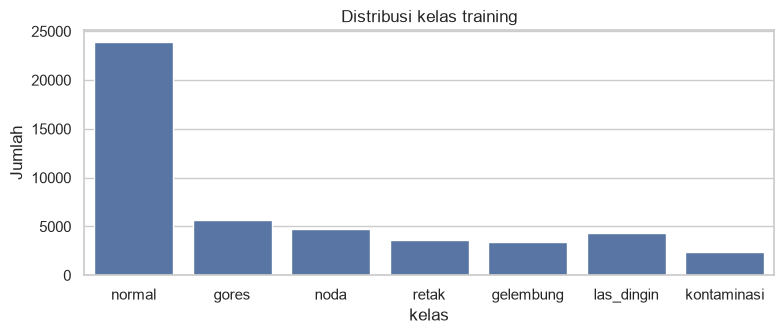

Baseline selalu 'normal': Accuracy = 0.4977 | Macro-F1 = 0.0949


In [3]:
# Distribusi kelas dan baseline mayoritas
class_counts = train_meta["kelas"].value_counts().reindex(CLASS_NAMES)
display(pd.DataFrame({"Jumlah": class_counts, "Persen": (class_counts / len(train_meta) * 100).round(2)}))
plt.figure(figsize=(8, 3.5)); sns.barplot(x=class_counts.index, y=class_counts.values, color="#4C72B0")
plt.title("Distribusi kelas training"); plt.ylabel("Jumlah"); plt.tight_layout(); plt.show()

maj = class_counts.idxmax(); y_maj = np.full(len(train_meta), maj)
print(f"Baseline selalu '{maj}': Accuracy = {accuracy_score(train_meta['kelas'], y_maj):.4f} | "
      f"Macro-F1 = {f1_score(train_meta['kelas'], y_maj, average='macro', labels=CLASS_NAMES, zero_division=0):.4f}")

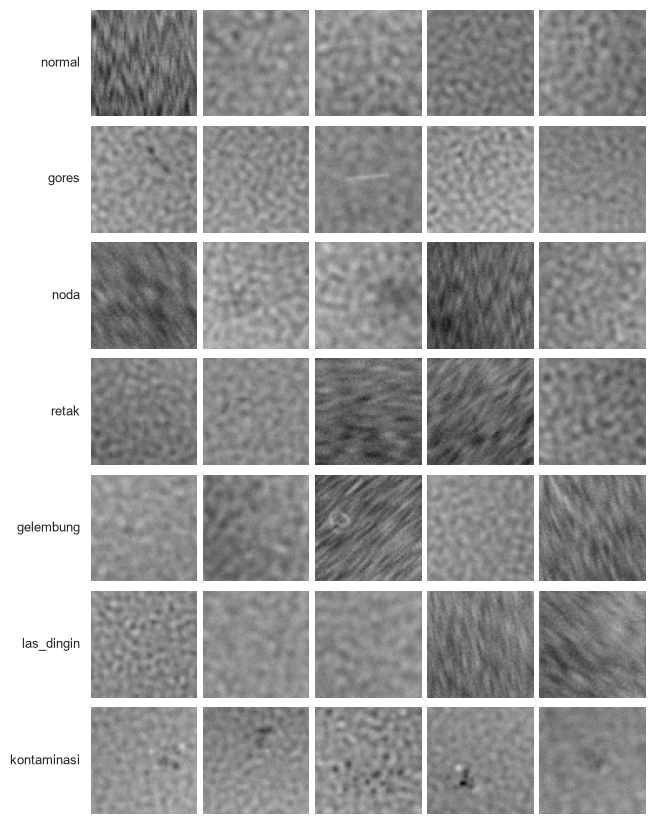

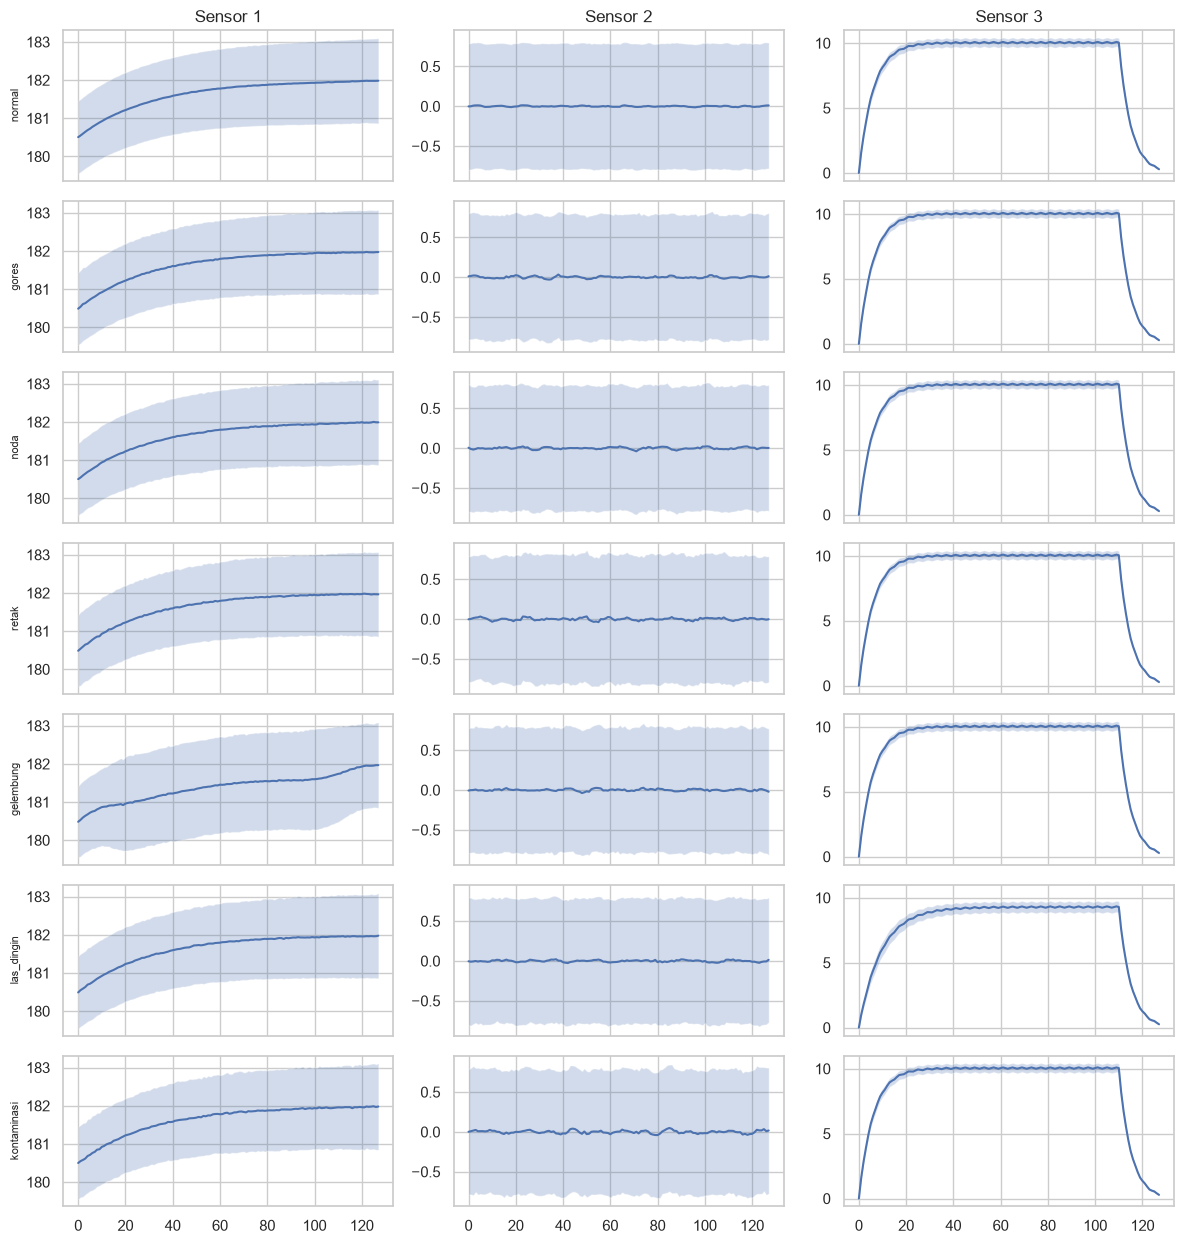

In [4]:
# Contoh gambar per kelas (acak, seed tetap)
rng = np.random.default_rng(SEED); N_SHOW = 5
fig, axes = plt.subplots(NUM_CLASSES, N_SHOW, figsize=(N_SHOW * 1.5, NUM_CLASSES * 1.5))
for r, c in enumerate(CLASS_NAMES):
    pool = np.where(train_meta["kelas"].to_numpy() == c)[0]
    for j, i in enumerate(rng.choice(pool, N_SHOW, replace=False)):
        axes[r, j].imshow(X_img[i], cmap="gray", vmin=0, vmax=255); axes[r, j].axis("off")
    axes[r, 0].text(-0.1, 0.5, c, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
fig.subplots_adjust(left=0.16, wspace=0.05, hspace=0.05); plt.show()

# Sinyal sensor per kelas: rata-rata dan std dari sampel valid
kelas_arr, t = train_meta["kelas"].to_numpy(), np.arange(SEQ_LEN)
fig, axes = plt.subplots(NUM_CLASSES, N_CHANNELS, figsize=(12, 1.8 * NUM_CLASSES), sharex=True, sharey="col")
for r, c in enumerate(CLASS_NAMES):
    for ch in range(N_CHANNELS):
        v = X_sensor[kelas_arr == c][:, ch, :]
        m, s = np.nanmean(v, 0), np.nanstd(v, 0)
        axes[r, ch].plot(t, m); axes[r, ch].fill_between(t, m - s, m + s, alpha=0.25)
        if r == 0: axes[r, ch].set_title(f"Sensor {ch + 1}")
        if ch == 0: axes[r, ch].set_ylabel(c, fontsize=8)
plt.tight_layout(); plt.show()

In [5]:
# Sensor hilang: per channel utuh atau parsial? Apakah terkait kelas, lini, shift?
def missing_report(X):
    nan = np.isnan(X); ch = nan.all(axis=2); n = ch.sum(1)
    return {"Total NaN (%)": round(nan.mean() * 100, 2), ">=1 channel hilang": int((n >= 1).sum()),
            "tepat 1 channel": int((n == 1).sum()), "tepat 2 channel": int((n == 2).sum()),
            "semua sensor hilang": int((n == 3).sum()), "NaN parsial": int((nan.any(2) & ~ch).sum())}
display(pd.DataFrame({"Train": missing_report(X_sensor), "Test": missing_report(X_sensor_test)}))

tr_any = np.isnan(X_sensor).all(2).any(1); tr_all = np.isnan(X_sensor).all(2).all(1)
te_any = np.isnan(X_sensor_test).all(2).any(1)
for nama, flag in [(">=1 channel hilang", tr_any), ("semua sensor hilang", tr_all)]:
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(train_meta["kelas"], flag))
    print(f"Chi-square missing ({nama}) vs kelas: p = {p:.4f}")
for col in ["lini", "shift"]:
    print(f"\nMissing rate (%) per {col}:")
    display(pd.DataFrame({"Train": train_meta.assign(m=tr_any).groupby(col)["m"].mean() * 100,
                          "Test": test_meta.assign(m=te_any).groupby(col)["m"].mean() * 100}).round(2).T)

,Train,Test
Total NaN (%),5.95,6.09
>=1 channel hilang,3863.00,1298.00
tepat 1 channel,1511.00,485.00
tepat 2 channel,0.00,0.00
semua sensor hilang,2352.00,813.00
NaN parsial,0.00,0.00


Chi-square missing (>=1 channel hilang) vs kelas: p = 0.3706
Chi-square missing (semua sensor hilang) vs kelas: p = 0.1552

Missing rate (%) per lini:


lini,A,B
Train,8.09,7.91
Test,8.24,8.03



Missing rate (%) per shift:


shift,malam,pagi,siang
Train,8.19,7.86,8.09
Test,8.80,7.73,7.80


In [6]:
# Perbedaan train vs test: proporsi lini/shift dan statistik gambar/sensor per lini (tanpa label test)
for col in ["lini", "shift"]:
    display((pd.DataFrame({"Train": train_meta[col].value_counts(normalize=True),
                           "Test": test_meta[col].value_counts(normalize=True)}) * 100).round(1).T)

def domain_frame(Xi, Xs, meta, tag):
    im = np.concatenate([Xi[i:i + 4000].reshape(len(Xi[i:i + 4000]), -1).astype(np.float32).mean(1) for i in range(0, len(Xi), 4000)])
    sd = np.concatenate([Xi[i:i + 4000].reshape(len(Xi[i:i + 4000]), -1).astype(np.float32).std(1) for i in range(0, len(Xi), 4000)])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); sm = np.nanmean(Xs, axis=2)
    return pd.DataFrame({"domain": tag + "-" + meta["lini"].to_numpy(), "img_mean": im, "img_std": sd,
                         "S1": sm[:, 0], "S2": sm[:, 1], "S3": sm[:, 2]})
dom = pd.concat([domain_frame(X_img, X_sensor, train_meta, "train"), domain_frame(X_img_test, X_sensor_test, test_meta, "test")])
display(dom.groupby("domain").mean().loc[["train-A", "train-B", "test-A", "test-B"]].round(3))

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(train_meta["lini"], train_meta["kelas"]))
print(f"Chi-square kelas vs lini (train): p = {p:.4f}")
print("Mesin per lini (train):", train_meta.groupby("lini")["id_mesin"].unique().apply(list).to_dict())

lini,A,B
Train,74.9,25.1
Test,40.0,60.0


shift,malam,pagi,siang
Train,33.5,33.0,33.4
Test,33.4,33.7,32.9


,img_mean,img_std,S1,S2,S3
domain,,,,,
train-A,139.791000,12.776,181.119995,0.000,8.473
train-B,111.732002,17.136,183.115005,0.000,8.416
test-A,139.888000,12.773,181.115997,-0.000,8.477
test-B,111.653999,17.125,183.126999,0.001,8.413


Chi-square kelas vs lini (train): p = 0.9778
Mesin per lini (train): {'A': ['M05', 'M04', 'M06', 'M03', 'M02', 'M01'], 'B': ['M09', 'M08', 'M11', 'M07', 'M12', 'M10']}


Ringkasan temuan: (1) kelas tidak seimbang, `normal` hampir 50% dan `kontaminasi` sekitar 5%, jadi dipakai Macro-F1; (2) sensor hilang per channel utuh (0, 1, atau 3 channel) dan tidak terkait kelas, jadi cukup mask + modality dropout; (3) komposisi lini terbalik (lini A 75% di train, 40% di test) dan gambar lini B lebih gelap dan kontras, jadi F1 dilaporkan per lini; (4) skala tiga sensor berbeda jauh, jadi distandardisasi per channel.

## 4. Preprocessing dan Split
Split 80/20 stratified menurut kelas x lini. Statistik imputasi dan normalisasi dihitung dari data train saja (tanpa kebocoran ke validation/test).

In [7]:
def channel_missing_mask(raw):
    nan = np.isnan(raw); ch = nan.all(axis=2)
    assert (nan.any(axis=2) == ch).all(), "Ada NaN parsial"
    return ch.astype(np.float32)

def fit_sensor_stats(raw):
    valid = ~np.isnan(raw); cnt = valid.sum(0)
    sums = np.nansum(raw, axis=0, dtype=np.float64)
    all_mean = np.nanmean(raw, axis=(0, 2), dtype=np.float64)
    time_means = np.where(cnt > 0, sums / np.maximum(cnt, 1), all_mean[:, None])
    mean, std = np.zeros(N_CHANNELS), np.zeros(N_CHANNELS)
    for ch in range(N_CHANNELS):
        v = raw[:, ch, :][valid[:, ch, :]].astype(np.float64); mean[ch], std[ch] = v.mean(), v.std()
    std[std == 0] = 1.0
    fill = (time_means - mean[:, None]) / std[:, None]
    return {k: v.astype(np.float32) for k, v in dict(time_means=time_means, ch_mean=mean, ch_std=std, fill_template=fill).items()}

def transform_sensor(raw, st):
    mask = channel_missing_mask(raw)
    filled = np.where(np.isnan(raw), st["time_means"][None], raw)
    return ((filled - st["ch_mean"][None, :, None]) / st["ch_std"][None, :, None]).astype(np.float32), mask

def make_sensor_input(sensor_norm, mask):   # (B,3,128) + mask (B,3) -> (B,6,128)
    return torch.cat([sensor_norm, mask.unsqueeze(-1).expand(-1, -1, sensor_norm.shape[-1])], dim=1)

y_all = train_meta["kelas"].map(LABEL2ID).to_numpy().astype(np.int64)
strata = (train_meta["kelas"] + "_" + train_meta["lini"]).to_numpy()
train_idx, val_idx = train_test_split(np.arange(len(train_meta)), test_size=VAL_SIZE, random_state=SEED, stratify=strata)
train_idx, val_idx = np.sort(train_idx), np.sort(val_idx)
sensor_stats = fit_sensor_stats(X_sensor[train_idx])           # hanya data TRAIN

def build_split(idx, img, sensor_raw, meta, labels=None):
    idx = np.arange(len(meta)) if idx is None else idx
    s, m = transform_sensor(sensor_raw[idx], sensor_stats)
    d = {"img": torch.from_numpy(img[idx]).unsqueeze(1),       # uint8 (N,1,64,64); dibagi 255 saat batch
         "sensor": torch.from_numpy(s), "mask": torch.from_numpy(m),
         "lini": meta["lini"].to_numpy()[idx], "id_unit": meta["id_unit"].to_numpy()[idx]}
    if labels is not None:
        d["y"] = torch.from_numpy(labels[idx])
    return d

data = {"train": build_split(train_idx, X_img, X_sensor, train_meta, y_all),
        "val": build_split(val_idx, X_img, X_sensor, train_meta, y_all),
        "test": build_split(None, X_img_test, X_sensor_test, test_meta)}

# Validasi preprocessing
for n, d in data.items():
    assert torch.isfinite(d["sensor"]).all() and torch.isfinite(d["mask"]).all(), n
obs = [data["train"]["sensor"][:, c][data["train"]["mask"][:, c] == 0] for c in range(N_CHANNELS)]
assert all(abs(o.mean()) < 1e-3 and abs(o.std() - 1) < 1e-3 for o in obs), "Standardisasi tidak benar"
i, ch = np.argwhere(data["train"]["mask"].numpy() == 1)[0]
assert np.allclose(data["train"]["sensor"][i, ch].numpy(), sensor_stats["fill_template"][ch], atol=1e-5)
assert len(set(train_idx) & set(val_idx)) == 0

display(pd.DataFrame({n: {"Sampel": len(d["mask"]), "Ada channel hilang": int((d["mask"].sum(1) >= 1).sum()),
                          "Semua sensor hilang": int((d["mask"].sum(1) == N_CHANNELS).sum())} for n, d in data.items()}).T)
va = train_meta.iloc[val_idx]
print("Validation per kelas dan lini (n):"); display(pd.crosstab(va["kelas"], va["lini"]).reindex(CLASS_NAMES).T)

np.savez(ARTIFACT_DIR / "split_indices.npz", train_idx=train_idx, val_idx=val_idx)
np.savez(ARTIFACT_DIR / "sensor_stats.npz", **sensor_stats)

,Sampel,Ada channel hilang,Semua sensor hilang
train,38400,3070,1863
val,9600,793,489
test,16000,1298,813


Validation per kelas dan lini (n):


kelas,normal,gores,noda,retak,gelembung,las_dingin,kontaminasi
lini,,,,,,,
A,3573,846,714,540,515,650,355
B,1205,278,241,181,171,215,116


## 5. Arsitektur dan Fungsi Training (poin b)
- Image encoder: CNN 2D kecil. Signal encoder: 1D-CNN dengan input sensor + mask `(6,128)`. Keduanya menghasilkan embedding 128 dimensi.
- Fusion: **concat** (gabung embedding) dan **gated** (gate sigmoid memilih porsi gambar vs sensor).
- Training: AdamW + OneCycle, mixed precision, early stopping pada validation Macro-F1.

In [8]:
EMB_DIM = 128
USE_AMP = DEVICE.type == "cuda"
DEFAULT_CFG = dict(epochs=EPOCHS, bs=256, lr=2e-3, wd=1e-4, patience=4, dropout=0.2, label_smoothing=0.0,
                   aug=False, line_norm=False, moddrop=False, p_all=0.25, p_ch=0.10)

def conv_block(ci, co):
    return nn.Sequential(nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True))
def conv1d_block(ci, co, stride=1):
    return nn.Sequential(nn.Conv1d(ci, co, 5, stride=stride, padding=2, bias=False), nn.BatchNorm1d(co), nn.ReLU(inplace=True))

class ImageEncoder(nn.Module):
    def __init__(self, drop=0.2):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 16), nn.MaxPool2d(2),
                                      conv_block(16, 32), conv_block(32, 32), nn.MaxPool2d(2),
                                      conv_block(32, 64), conv_block(64, 64), nn.MaxPool2d(2),
                                      conv_block(64, 128))
        self.proj = nn.Sequential(nn.Dropout(drop), nn.Linear(256, EMB_DIM), nn.ReLU(inplace=True))
    def forward(self, x):
        f = self.features(x)
        return self.proj(torch.cat([f.mean((2, 3)), f.amax((2, 3))], 1))

class SignalEncoder(nn.Module):
    def __init__(self, drop=0.2):
        super().__init__()
        self.features = nn.Sequential(conv1d_block(2 * N_CHANNELS, 32), conv1d_block(32, 64, 2),
                                      conv1d_block(64, 128, 2), conv1d_block(128, 128, 2))
        self.proj = nn.Sequential(nn.Dropout(drop), nn.Linear(256, EMB_DIM), nn.ReLU(inplace=True))
    def forward(self, x):
        f = self.features(x)
        return self.proj(torch.cat([f.mean(2), f.amax(2)], 1))

def make_head(d_in, drop):
    return nn.Sequential(nn.Linear(d_in, 128), nn.ReLU(inplace=True), nn.Dropout(drop), nn.Linear(128, NUM_CLASSES))

class ImageOnlyNet(nn.Module):
    def __init__(self, drop):
        super().__init__(); self.img_enc, self.head = ImageEncoder(drop), make_head(EMB_DIM, drop)
    def forward(self, img, sensor, mask):
        return self.head(self.img_enc(img))

class SensorOnlyNet(nn.Module):
    def __init__(self, drop):
        super().__init__(); self.sig_enc, self.head = SignalEncoder(drop), make_head(EMB_DIM, drop)
    def forward(self, img, sensor, mask):
        return self.head(self.sig_enc(make_sensor_input(sensor, mask)))

class ConcatFusionNet(nn.Module):
    def __init__(self, drop):
        super().__init__(); self.img_enc, self.sig_enc = ImageEncoder(drop), SignalEncoder(drop)
        self.head = make_head(2 * EMB_DIM, drop)
    def forward(self, img, sensor, mask):
        return self.head(torch.cat([self.img_enc(img), self.sig_enc(make_sensor_input(sensor, mask))], 1))

class GatedFusionNet(nn.Module):
    def __init__(self, drop):
        super().__init__(); self.img_enc, self.sig_enc = ImageEncoder(drop), SignalEncoder(drop)
        self.gate, self.head = nn.Linear(2 * EMB_DIM + N_CHANNELS, EMB_DIM), make_head(EMB_DIM, drop)
    def forward(self, img, sensor, mask):
        hi, hs = self.img_enc(img), self.sig_enc(make_sensor_input(sensor, mask))
        g = torch.sigmoid(self.gate(torch.cat([hi, hs, mask.to(hi.dtype)], 1)))   # g = porsi gambar
        self.last_gate = g.detach()
        return self.head(g * hi + (1 - g) * hs)

ARCH = {"image": ImageOnlyNet, "sensor": SensorOnlyNet, "concat": ConcatFusionNet, "gated": GatedFusionNet}
def build_model(arch, cfg):
    return ARCH[arch](cfg["dropout"])

# Uji bentuk dan jumlah parameter
xb = {k: data["train"][k][:8].to(DEVICE) for k in ["sensor", "mask"]}; xb["img"] = data["train"]["img"][:8].to(DEVICE).float() / 255
rows = []
for a in ARCH:
    m = build_model(a, DEFAULT_CFG).to(DEVICE).eval()
    with torch.no_grad():
        assert m(xb["img"], xb["sensor"], xb["mask"]).shape == (8, NUM_CLASSES)
    rows.append({"Model": a, "Parameter (K)": round(sum(p.numel() for p in m.parameters()) / 1e3)})
display(pd.DataFrame(rows).set_index("Model").T); del xb, m

Model,image,sensor,concat,gated
Parameter (K),194,185,378,395


In [9]:
# Data di GPU (gambar uint8), augmentation, modality dropout, dan loader
def to_gpu(d):
    g = {k: d[k].to(DEVICE) for k in ["img", "sensor", "mask"] + (["y"] if "y" in d else [])}
    g["lid"] = torch.as_tensor((d["lini"] == "B").astype(np.int64), device=DEVICE)   # 0 = lini A, 1 = lini B
    g["n"] = len(d["mask"])
    return g

def subset_gd(g, idx):
    i = torch.as_tensor(idx, device=DEVICE)
    out = {k: g[k][i] for k in ["img", "sensor", "mask", "lid"] + (["y"] if "y" in g else [])}
    out["n"] = len(idx); return out

GD = {"train": to_gpu(data["train"]), "val": to_gpu(data["val"])}
Y_VAL, LINI_VAL = data["val"]["y"].numpy(), data["val"]["lini"]
p_test, p_val = test_meta["lini"].value_counts(normalize=True), pd.Series(LINI_VAL).value_counts(normalize=True)
W_VAL = pd.Series(LINI_VAL).map(p_test / p_val).to_numpy()      # bobot validation ke proporsi lini test (metadata saja)
MASK_SUM_VAL = data["val"]["mask"].sum(1).numpy()
FILL_BASE = torch.from_numpy(sensor_stats["fill_template"]).to(DEVICE); FILL_ZERO = torch.zeros_like(FILL_BASE)

def fit_line_stats(g):   # mean/std gambar dan sensor per lini, hanya dari train
    im_m, im_s, se_m, se_s = [], [], [], []
    for k in (0, 1):
        sel = (g["lid"] == k).nonzero().squeeze(1)
        s1 = s2 = 0.0; n = 0
        for part in sel.split(4096):
            x = g["img"][part].double() / 255
            s1 += x.sum().item(); s2 += (x * x).sum().item(); n += x.numel()
        m = s1 / n; im_m.append(m); im_s.append(max(s2 / n - m * m, 1e-12) ** 0.5)
        sen, msk = g["sensor"][sel], g["mask"][sel]
        v = [sen[:, c, :][msk[:, c] == 0] for c in range(N_CHANNELS)]
        se_m.append(torch.stack([x.mean() for x in v])); se_s.append(torch.stack([x.std() for x in v]))
    f = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
    return {"img_m": f(im_m), "img_s": f(im_s), "sen_m": torch.stack(se_m), "sen_s": torch.stack(se_s)}
LINE_STATS = fit_line_stats(GD["train"])

def augment_image(x):   # jitter kecerahan/kontras + noise ringan (meniru beda tampilan antar lini)
    B = x.size(0); m = x.mean((1, 2, 3), keepdim=True)
    c = torch.empty(B, 1, 1, 1, device=x.device).uniform_(0.75, 1.35)
    b = torch.empty(B, 1, 1, 1, device=x.device).uniform_(-0.15, 0.15)
    return ((x - m) * c + m + b + 0.02 * torch.randn_like(x)).clamp(0, 1)

def augment_sensor(s, mask):
    obs = (1 - mask).unsqueeze(-1)
    return s + (0.2 * torch.randn(s.size(0), N_CHANNELS, 1, device=s.device) + 0.05 * torch.randn_like(s)) * obs

def apply_drop(sen, mask, drop, fill):   # drop (B,3) bool: channel diganti template dan mask = 1
    sen = torch.where(drop.unsqueeze(-1), fill.unsqueeze(0).expand_as(sen), sen)
    return sen, torch.maximum(mask, drop.float())

def modality_dropout(sen, mask, fill, p_all, p_ch):   # gambar tidak pernah dibuang
    B = sen.size(0)
    drop = (torch.rand(B, N_CHANNELS, device=sen.device) < p_ch) | (torch.rand(B, 1, device=sen.device) < p_all)
    return apply_drop(sen, mask, drop, fill)

def prepare_batch(img, sen, mask, lid, cfg, train):
    img = img.float().div_(255.0); fill = FILL_BASE
    if train and cfg["aug"]:
        img = augment_image(img)
    if cfg["line_norm"]:
        img = (img - LINE_STATS["img_m"][lid].view(-1, 1, 1, 1)) / LINE_STATS["img_s"][lid].view(-1, 1, 1, 1)
        sen = (sen - LINE_STATS["sen_m"][lid].unsqueeze(-1)) / LINE_STATS["sen_s"][lid].unsqueeze(-1)
        sen, fill = sen * (1.0 - mask).unsqueeze(-1), FILL_ZERO
    if train and cfg["aug"]:
        sen = augment_sensor(sen, mask)
    if train and cfg["moddrop"]:
        sen, mask = modality_dropout(sen, mask, fill, cfg["p_all"], cfg["p_ch"])
    return img, sen, mask, fill

class TensorBatchDataset(Dataset):
    def __init__(self, g): self.g = g
    def __len__(self): return self.g["n"]
    def __getitem__(self, idx):
        i = torch.as_tensor(idx, device=DEVICE)
        y = self.g["y"][i] if "y" in self.g else torch.zeros(len(idx), dtype=torch.long, device=DEVICE)
        return self.g["img"][i], self.g["sensor"][i], self.g["mask"][i], self.g["lid"][i], y

def make_loader(g, bs, shuffle, seed=0):
    ds = TensorBatchDataset(g)
    if shuffle:
        gen = torch.Generator(); gen.manual_seed(seed); base = RandomSampler(ds, generator=gen)
    else:
        base = SequentialSampler(ds)
    return DataLoader(ds, sampler=BatchSampler(base, bs, drop_last=shuffle), batch_size=None, num_workers=0)

In [10]:
RUNS = {}

def compute_metrics(y, pred):
    L = list(range(NUM_CLASSES))
    return {"acc": accuracy_score(y, pred), "prec": precision_score(y, pred, average="macro", labels=L, zero_division=0),
            "rec": recall_score(y, pred, average="macro", labels=L, zero_division=0),
            "f1": f1_score(y, pred, average="macro", labels=L, zero_division=0)}

def macro_f1(y, pred, **kw):
    return f1_score(y, pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0, **kw)

@torch.no_grad()
def predict_logits(model, g, cfg, drop_channels=None, return_gate=False, bs=1024):
    model.eval(); outs, gates = [], []
    for img, sen, mask, lid, _ in make_loader(g, bs, False):
        img, sen, mask, fill = prepare_batch(img, sen, mask, lid, cfg, train=False)
        if drop_channels:
            d = torch.zeros(sen.size(0), N_CHANNELS, dtype=torch.bool, device=sen.device); d[:, drop_channels] = True
            sen, mask = apply_drop(sen, mask, d, fill)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            lg = model(img, sen, mask)
        outs.append(lg.float().cpu())
        if return_gate and hasattr(model, "last_gate"):
            gates.append(model.last_gate.float().mean(1).cpu())
    out = torch.cat(outs)
    return (out, torch.cat(gates).numpy() if gates else None) if return_gate else out

def evaluate_run(run):
    logits = predict_logits(run["model"], GD["val"], run["cfg"]); pred = logits.argmax(1).numpy()
    m = compute_metrics(Y_VAL, pred)
    for l in ["A", "B"]:
        m[f"f1_{l}"] = macro_f1(Y_VAL[LINI_VAL == l], pred[LINI_VAL == l])
    m["f1_w"] = macro_f1(Y_VAL, pred, sample_weight=W_VAL)
    run["val_logits"], run["val_metrics"] = logits, m

def train_run(name, arch, cfg_over=None, seed=SEED, train_y=None):
    cfg = {**DEFAULT_CFG, **(cfg_over or {}), "arch": arch, "seed": seed}
    ckpt, hpath = ARTIFACT_DIR / f"ckpt_{name}.pt", ARTIFACT_DIR / f"hist_{name}.json"
    set_seed(seed); model = build_model(arch, cfg).to(DEVICE)
    params = sum(p.numel() for p in model.parameters())
    if ckpt.exists() and hpath.exists() and not FORCE_RETRAIN:
        state = torch.load(ckpt, map_location=DEVICE, weights_only=True)
        if state["cfg"] == cfg:
            model.load_state_dict(state["model"])
            run = dict(name=name, arch=arch, cfg=cfg, model=model, history=pd.DataFrame(json.load(open(hpath))),
                       best_epoch=state["best_epoch"], params=params, time_s=state["time_s"], ckpt=ckpt)
            RUNS[name] = run; evaluate_run(run)
            print(f"[{name}] checkpoint dimuat | val Macro-F1 {run['val_metrics']['f1']:.4f}"); return run
    tg = GD["train"] if train_y is None else {**GD["train"], "y": torch.as_tensor(train_y, device=DEVICE)}
    loader = make_loader(tg, cfg["bs"], True, seed)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * len(loader), pct_start=0.2)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    rows, best_f1, best_ep, best_state, bad, t0 = [], -1.0, 0, None, 0, time.time()
    print(f"[{name}] {arch} | {params / 1e3:.0f}K parameter")
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); tl, preds, ys = 0.0, [], []
        for img, sen, mask, lid, y in loader:
            img, sen, mask, _ = prepare_batch(img, sen, mask, lid, cfg, train=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(img, sen, mask)
            loss = crit(logits.float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step()
            tl += F.cross_entropy(logits.detach().float(), y, reduction="sum").item()
            preds.append(logits.argmax(1)); ys.append(y)
        tr_loss = tl / sum(len(p) for p in preds)
        tr_f1 = macro_f1(torch.cat(ys).cpu().numpy(), torch.cat(preds).cpu().numpy())
        vl = predict_logits(model, GD["val"], cfg)
        va_loss = F.cross_entropy(vl, torch.as_tensor(Y_VAL)).item(); va = compute_metrics(Y_VAL, vl.argmax(1).numpy())
        rows.append({"epoch": ep, "train_loss": tr_loss, "val_loss": va_loss, "train_f1": tr_f1, "val_f1": va["f1"]})
        print(f"  ep {ep:2d} | loss {tr_loss:.3f} / {va_loss:.3f} | macro-F1 {tr_f1:.3f} / {va['f1']:.3f}")
        if va["f1"] > best_f1 + 1e-4:
            best_f1, best_ep, bad = va["f1"], ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["patience"]:
                print(f"  early stopping (terbaik di epoch {best_ep})"); break
    model.load_state_dict(best_state); hist = pd.DataFrame(rows); elapsed = time.time() - t0
    torch.save({"model": best_state, "cfg": cfg, "best_epoch": best_ep, "time_s": elapsed}, ckpt)
    json.dump(hist.to_dict("list"), open(hpath, "w"))
    run = dict(name=name, arch=arch, cfg=cfg, model=model, history=hist, best_epoch=best_ep, params=params, time_s=elapsed, ckpt=ckpt)
    RUNS[name] = run; evaluate_run(run)
    print(f"[{name}] selesai {elapsed:.0f} detik | val Macro-F1 {run['val_metrics']['f1']:.4f}")
    return run

def metrics_table(names, labels=None):
    rows = []
    for n in names:
        m = RUNS[n]["val_metrics"]
        rows.append({"Model": (labels or {}).get(n, n), "Accuracy": m["acc"], "Precision": m["prec"], "Recall": m["rec"],
                     "Macro-F1": m["f1"], "F1 lini A": m["f1_A"], "F1 lini B": m["f1_B"], "F1 terbobot lini test": m["f1_w"]})
    return pd.DataFrame(rows).set_index("Model").round(4)

def plot_history(run, title=None):
    h = run["history"]; fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for a, (k1, k2, yl) in zip(ax, [("train_loss", "val_loss", "Cross Entropy"), ("train_f1", "val_f1", "Macro-F1")]):
        a.plot(h["epoch"], h[k1], marker="o", ms=3, label="Train"); a.plot(h["epoch"], h[k2], marker="o", ms=3, label="Validation")
        a.axvline(run["best_epoch"], ls="--", c="gray", lw=1, label="Epoch terbaik"); a.set_xlabel("Epoch"); a.set_ylabel(yl); a.legend()
    fig.suptitle(title or run["name"]); plt.tight_layout(); plt.show()

def diagnose_fit(run):
    h = run["history"]; r = h[h["epoch"] == run["best_epoch"]].iloc[0]; gap = r["train_f1"] - r["val_f1"]
    kesimpulan = "ada indikasi overfitting" if gap > 0.05 else ("indikasi underfitting" if r["val_f1"] < 0.5 else "tidak ada overfitting berarti")
    print(f"Epoch terbaik {run['best_epoch']}: train F1 {r['train_f1']:.3f}, val F1 {r['val_f1']:.3f} (selisih {gap:+.3f}) -> {kesimpulan}.")

## 6. Nilai Tiap Modalitas dan Perbandingan Fusion (poin b, c)
Image-only, sensor-only, dan dua strategi fusion dilatih dengan split, seed, dan hyperparameter yang sama.

[image_only] checkpoint dimuat | val Macro-F1 0.5948
[sensor_only] checkpoint dimuat | val Macro-F1 0.4512
[concat_fusion] checkpoint dimuat | val Macro-F1 0.8343
[gated_fusion] gated | 395K parameter
  ep  1 | loss 1.479 / 1.015 | macro-F1 0.213 / 0.411
  ep  2 | loss 0.874 / 0.837 | macro-F1 0.571 / 0.604
  ep  3 | loss 0.733 / 0.750 | macro-F1 0.651 / 0.641
  ep  4 | loss 0.663 / 0.762 | macro-F1 0.695 / 0.631
  ep  5 | loss 0.622 / 0.634 | macro-F1 0.715 / 0.699
  ep  6 | loss 0.567 / 0.533 | macro-F1 0.751 / 0.788
  ep  7 | loss 0.487 / 0.510 | macro-F1 0.813 / 0.803
  ep  8 | loss 0.456 / 0.588 | macro-F1 0.828 / 0.779
  ep  9 | loss 0.420 / 0.493 | macro-F1 0.841 / 0.820
  ep 10 | loss 0.391 / 0.482 | macro-F1 0.855 / 0.817
  ep 11 | loss 0.363 / 0.467 | macro-F1 0.864 / 0.821
  ep 12 | loss 0.343 / 0.456 | macro-F1 0.871 / 0.833
  ep 13 | loss 0.321 / 0.458 | macro-F1 0.882 / 0.833
  ep 14 | loss 0.313 / 0.461 | macro-F1 0.883 / 0.835
[gated_fusion] selesai 3734 detik | val Mac

,Accuracy,Precision,Recall,Macro-F1,F1 lini A,F1 lini B,F1 terbobot lini test
Model,,,,,,,
Image-only,0.7302,0.6525,0.5664,0.5948,0.6464,0.3796,0.5092
Sensor-only,0.6621,0.4585,0.4604,0.4512,0.4567,0.4337,0.4433
Concat fusion,0.8643,0.8679,0.8067,0.8343,0.8724,0.7052,0.7772
Gated fusion,0.8641,0.8737,0.8031,0.8346,0.8697,0.7118,0.7812


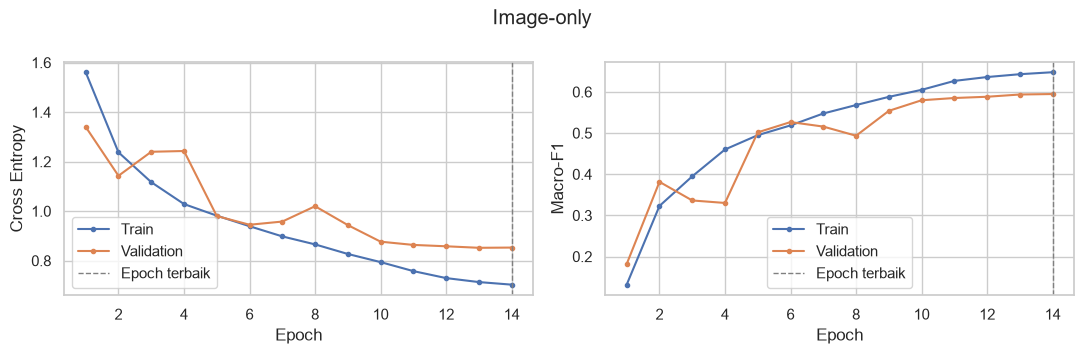

Epoch terbaik 14: train F1 0.648, val F1 0.595 (selisih +0.053) -> ada indikasi overfitting.


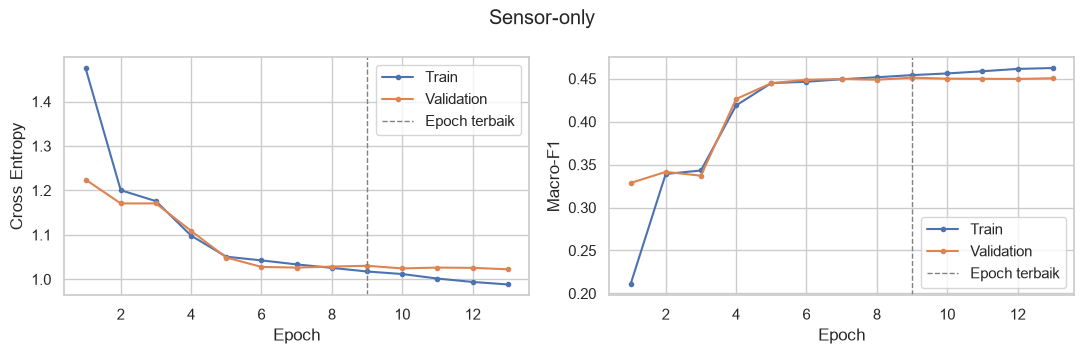

Epoch terbaik 9: train F1 0.454, val F1 0.451 (selisih +0.003) -> indikasi underfitting.

Fusion terbaik: Gated fusion (val Macro-F1 0.8346)


,Image-only,Sensor-only,Concat fusion,Gated fusion
normal,0.819,0.745,0.906,0.904
gores,0.649,0.000,0.713,0.714
noda,0.857,0.000,0.864,0.863
retak,0.458,0.702,0.737,0.736
gelembung,0.520,0.770,0.801,0.802
las_dingin,0.000,0.941,0.943,0.943
kontaminasi,0.860,0.000,0.876,0.881


  normal      : image 0.82 | sensor 0.75 | fusion 0.90 -> keduanya berperan
  gores       : image 0.65 | sensor 0.00 | fusion 0.71 -> terutama gambar
  noda        : image 0.86 | sensor 0.00 | fusion 0.86 -> terutama gambar
  retak       : image 0.46 | sensor 0.70 | fusion 0.74 -> terutama sensor
  gelembung   : image 0.52 | sensor 0.77 | fusion 0.80 -> terutama sensor
  las_dingin  : image 0.00 | sensor 0.94 | fusion 0.94 -> terutama sensor
  kontaminasi : image 0.86 | sensor 0.00 | fusion 0.88 -> terutama gambar

Gate gated fusion (porsi gambar): sensor lengkap 0.541 | sensor hilang semua 0.545


In [11]:
for n, a in [("image_only", "image"), ("sensor_only", "sensor"), ("concat_fusion", "concat"), ("gated_fusion", "gated")]:
    train_run(n, a)
LABELS = {"image_only": "Image-only", "sensor_only": "Sensor-only", "concat_fusion": "Concat fusion", "gated_fusion": "Gated fusion"}
NAMES_MAIN = list(LABELS)
display(metrics_table(NAMES_MAIN, LABELS))
plot_history(RUNS["image_only"], "Image-only"); diagnose_fit(RUNS["image_only"])
plot_history(RUNS["sensor_only"], "Sensor-only"); diagnose_fit(RUNS["sensor_only"])

BEST_NAME = max(["concat_fusion", "gated_fusion"], key=lambda n: RUNS[n]["val_metrics"]["f1"])
BEST_ARCH = RUNS[BEST_NAME]["arch"]
print(f"\nFusion terbaik: {LABELS[BEST_NAME]} (val Macro-F1 {RUNS[BEST_NAME]['val_metrics']['f1']:.4f})")

# Kelas mana butuh modalitas mana
pc = pd.DataFrame({LABELS[n]: f1_score(Y_VAL, RUNS[n]["val_logits"].argmax(1).numpy(), average=None,
                                       labels=list(range(NUM_CLASSES)), zero_division=0) for n in NAMES_MAIN}, index=CLASS_NAMES)
display(pc.round(3))
for c in CLASS_NAMES:
    i, s = pc.loc[c, "Image-only"], pc.loc[c, "Sensor-only"]
    kat = "terutama gambar" if i - s > 0.2 else ("terutama sensor" if s - i > 0.2 else "keduanya berperan")
    print(f"  {c:12s}: image {i:.2f} | sensor {s:.2f} | fusion {pc.loc[c, LABELS[BEST_NAME]]:.2f} -> {kat}")

_, g = predict_logits(RUNS["gated_fusion"]["model"], GD["val"], RUNS["gated_fusion"]["cfg"], return_gate=True)
print(f"\nGate gated fusion (porsi gambar): sensor lengkap {g[MASK_SUM_VAL == 0].mean():.3f} | sensor hilang semua {g[MASK_SUM_VAL == N_CHANNELS].mean():.3f}")

## 7. Label Tidak Sempurna (poin d)
Kandidat label bermasalah: loss termasuk 5% tertinggi pada minimal 2 dari 3 model dan prediksi mayoritas berbeda dari label. Label tidak diubah. Teknik robust yang diuji: label smoothing 0,1.

Kandidat: 1,785 dari 38,400 (4.65%)


,Kandidat,Persen kelas
label,,
normal,142,0.74
gores,370,8.22
noda,241,6.31
retak,447,15.49
gelembung,302,11.01
las_dingin,203,5.87
kontaminasi,80,4.24


Persen kandidat per lini: {'A': 3.31, 'B': 8.65}
Pasangan label -> prediksi terbanyak:


,,jumlah
label,prediksi_mayoritas,
gores,normal,305
retak,normal,285
las_dingin,normal,199
retak,gores,156
gelembung,normal,151


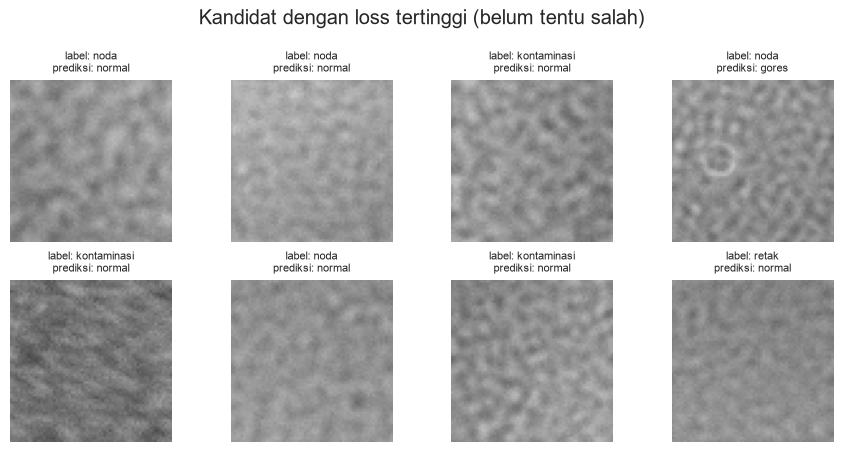

[gated_ls] gated | 395K parameter
  ep  1 | loss 1.482 / 1.005 | macro-F1 0.212 / 0.417
  ep  2 | loss 0.899 / 0.828 | macro-F1 0.574 / 0.594
  ep  3 | loss 0.761 / 0.989 | macro-F1 0.654 / 0.534
  ep  4 | loss 0.699 / 0.815 | macro-F1 0.698 / 0.663
  ep  5 | loss 0.602 / 0.723 | macro-F1 0.778 / 0.715
  ep  6 | loss 0.556 / 0.557 | macro-F1 0.805 / 0.804
  ep  7 | loss 0.529 / 0.570 | macro-F1 0.821 / 0.790
  ep  8 | loss 0.501 / 0.638 | macro-F1 0.836 / 0.773
  ep  9 | loss 0.469 / 0.525 | macro-F1 0.849 / 0.822
  ep 10 | loss 0.446 / 0.514 | macro-F1 0.858 / 0.828
  ep 11 | loss 0.423 / 0.501 | macro-F1 0.869 / 0.832
  ep 12 | loss 0.404 / 0.491 | macro-F1 0.877 / 0.836
  ep 13 | loss 0.384 / 0.485 | macro-F1 0.887 / 0.837
  ep 14 | loss 0.378 / 0.482 | macro-F1 0.890 / 0.839
[gated_ls] selesai 3679 detik | val Macro-F1 0.8385


,Accuracy,Precision,Recall,Macro-F1,F1 lini A,F1 lini B,F1 terbobot lini test
Model,,,,,,,
Cross Entropy,0.8641,0.8737,0.8031,0.8346,0.8697,0.7118,0.7812
Label smoothing 0.1,0.8660,0.8749,0.8083,0.8385,0.8744,0.7198,0.7855


Selisih val Macro-F1 (LS - CE): +0.0039


In [12]:
other = "gated_fusion" if BEST_NAME == "concat_fusion" else "concat_fusion"
cand_models = ["image_only", BEST_NAME, other]
y_tr = data["train"]["y"].numpy(); losses, preds = [], []
for n in cand_models:
    lg = predict_logits(RUNS[n]["model"], GD["train"], RUNS[n]["cfg"])
    losses.append(F.cross_entropy(lg, torch.as_tensor(y_tr), reduction="none").numpy()); preds.append(lg.argmax(1).numpy())
losses, preds = np.stack(losses), np.stack(preds)
votes = (losses > np.quantile(losses, 0.95, axis=1, keepdims=True)).sum(0)
major = stats.mode(preds, axis=0, keepdims=False).mode
is_cand = (votes >= 2) & (major != y_tr)

cand = pd.DataFrame({"id_unit": data["train"]["id_unit"], "lini": data["train"]["lini"], "label": [ID2LABEL[i] for i in y_tr],
                     "prediksi_mayoritas": [ID2LABEL[i] for i in major], "loss": losses.mean(0)})[is_cand].sort_values("loss", ascending=False)
cand.to_csv(ARTIFACT_DIR / "kandidat_label_bermasalah.csv", index=False)
tot = pd.Series(train_meta.iloc[train_idx]["kelas"]).value_counts()
print(f"Kandidat: {len(cand):,} dari {len(y_tr):,} ({len(cand) / len(y_tr) * 100:.2f}%)")
display(pd.DataFrame({"Kandidat": cand["label"].value_counts(), "Persen kelas": (cand["label"].value_counts() / tot * 100).round(2)}).reindex(CLASS_NAMES).fillna(0))
print("Persen kandidat per lini:", (cand["lini"].value_counts() / pd.Series(data["train"]["lini"]).value_counts() * 100).round(2).to_dict())
print("Pasangan label -> prediksi terbanyak:"); display(cand.groupby(["label", "prediksi_mayoritas"]).size().sort_values(ascending=False).head(5).rename("jumlah").to_frame())

pos = {u: i for i, u in enumerate(data["train"]["id_unit"])}
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for ax, (_, r) in zip(axes.ravel(), cand.head(8).iterrows()):
    ax.imshow(data["train"]["img"][pos[r["id_unit"]], 0], cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"label: {r['label']}\nprediksi: {r['prediksi_mayoritas']}", fontsize=8)
plt.suptitle("Kandidat dengan loss tertinggi (belum tentu salah)"); plt.tight_layout(); plt.show()

# Cross Entropy vs label smoothing pada label asli
run_ls = train_run(f"{BEST_ARCH}_ls", BEST_ARCH, {"label_smoothing": 0.1})
display(metrics_table([BEST_NAME, run_ls["name"]], {BEST_NAME: "Cross Entropy", run_ls["name"]: "Label smoothing 0.1"}))
print(f"Selisih val Macro-F1 (LS - CE): {run_ls['val_metrics']['f1'] - RUNS[BEST_NAME]['val_metrics']['f1']:+.4f}")

if RUN_NOISE_TEST:   # opsional: 15% label diacak (hanya train), validation tetap bersih
    r = np.random.default_rng(123); y_noisy = y_tr.copy(); sel = r.choice(len(y_tr), int(0.15 * len(y_tr)), replace=False)
    y_noisy[sel] = (y_tr[sel] + r.integers(1, NUM_CLASSES, len(sel))) % NUM_CLASSES
    n_ce = train_run(f"{BEST_ARCH}_noise_ce", BEST_ARCH, {"synthetic_noise": 0.15}, train_y=y_noisy)
    n_ls = train_run(f"{BEST_ARCH}_noise_ls", BEST_ARCH, {"synthetic_noise": 0.15, "label_smoothing": 0.1}, train_y=y_noisy)
    print(f"Noise 15%: CE {n_ce['val_metrics']['f1']:.4f} | LS {n_ls['val_metrics']['f1']:.4f}")

## 8. Domain Shift (poin e)
Macro-F1 validation diukur per lini. Teknik yang diuji: normalisasi per lini + augmentation kecerahan/kontras (satu run). "F1 terbobot" memberi bobot validation sesuai proporsi lini test.

In [13]:
run_dom = train_run(f"{BEST_ARCH}_dom", BEST_ARCH, {"line_norm": True, "aug": True})
rows = []
for k, n in [("Baseline", BEST_NAME), ("Per-line norm + augmentation", run_dom["name"])]:
    m = RUNS[n]["val_metrics"]
    rows.append({"Metode": k, "F1 lini A": m["f1_A"], "F1 lini B": m["f1_B"], "Selisih A-B": m["f1_A"] - m["f1_B"],
                 "Macro-F1": m["f1"], "F1 terbobot": m["f1_w"]})
display(pd.DataFrame(rows).set_index("Metode").round(4))

pb = RUNS[BEST_NAME]["val_logits"].argmax(1).numpy()
pcl = pd.DataFrame({f"Lini {l}": f1_score(Y_VAL[LINI_VAL == l], pb[LINI_VAL == l], average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
                    for l in ["A", "B"]}, index=CLASS_NAMES)
pcl["Selisih"] = pcl["Lini A"] - pcl["Lini B"]
print("F1 per kelas per lini (baseline):"); display(pcl.round(3))
print(f"Kelas paling terdampak: {pcl['Selisih'].idxmax()} (selisih {pcl['Selisih'].max():.3f})")

[gated_dom] gated | 395K parameter
  ep  1 | loss 1.489 / 1.024 | macro-F1 0.204 / 0.432
  ep  2 | loss 0.922 / 0.803 | macro-F1 0.540 / 0.598
  ep  3 | loss 0.818 / 0.838 | macro-F1 0.604 / 0.587
  ep  4 | loss 0.739 / 0.683 | macro-F1 0.640 / 0.670
  ep  5 | loss 0.694 / 0.668 | macro-F1 0.667 / 0.661
  ep  6 | loss 0.660 / 0.627 | macro-F1 0.688 / 0.708
  ep  7 | loss 0.627 / 0.683 | macro-F1 0.708 / 0.669
  ep  8 | loss 0.598 / 0.580 | macro-F1 0.729 / 0.744
  ep  9 | loss 0.539 / 0.503 | macro-F1 0.779 / 0.815
  ep 10 | loss 0.484 / 0.494 | macro-F1 0.818 / 0.820
  ep 11 | loss 0.455 / 0.481 | macro-F1 0.830 / 0.820
  ep 12 | loss 0.440 / 0.476 | macro-F1 0.834 / 0.823
  ep 13 | loss 0.426 / 0.473 | macro-F1 0.839 / 0.825
  ep 14 | loss 0.419 / 0.464 | macro-F1 0.842 / 0.829
[gated_dom] selesai 3290 detik | val Macro-F1 0.8288


,F1 lini A,F1 lini B,Selisih A-B,Macro-F1,F1 terbobot
Metode,,,,,
Baseline,0.8697,0.7118,0.1579,0.8346,0.7812
Per-line norm + augmentation,0.8580,0.7259,0.1321,0.8288,0.7842


F1 per kelas per lini (baseline):


,Lini A,Lini B,Selisih
normal,0.934,0.824,0.110
gores,0.794,0.384,0.410
noda,0.903,0.734,0.169
retak,0.783,0.574,0.209
gelembung,0.811,0.774,0.038
las_dingin,0.945,0.934,0.011
kontaminasi,0.918,0.759,0.159


Kelas paling terdampak: gores (selisih 0.410)


## 9. Sensor Hilang (poin f)
Uji terkendali pada validation yang sensornya lengkap: sensor dihilangkan secara buatan (S1, S2, S3, atau semua). Modality dropout saat training: semua sensor dibuang 25%, tiap channel 10%; gambar selalu dipertahankan.

In [14]:
run_md = train_run(f"{BEST_ARCH}_md", BEST_ARCH, {"moddrop": True})
COND = {"lengkap": [], "hilang S1": [0], "hilang S2": [1], "hilang S3": [2], "semua hilang": [0, 1, 2]}
FULL_IDX = np.where(MASK_SUM_VAL == 0)[0]; SUB = subset_gd(GD["val"], FULL_IDX); Y_SUB = Y_VAL[FULL_IDX]

COND_TABLE = {}
def cond_row(name):
    out = {c: macro_f1(Y_SUB, predict_logits(RUNS[name]["model"], SUB, RUNS[name]["cfg"], drop_channels=ch).argmax(1).numpy()) for c, ch in COND.items()}
    out["1 channel hilang (rata-rata)"] = np.mean([out["hilang S1"], out["hilang S2"], out["hilang S3"]])
    COND_TABLE[name] = out

cmp = {"image_only": "Image-only", "sensor_only": "Sensor-only", BEST_NAME: "Fusion tanpa modality dropout", run_md["name"]: "Fusion + modality dropout"}
for n in cmp: cond_row(n)
print(f"Subset sensor lengkap: {len(FULL_IDX):,} sampel")
display(pd.DataFrame({cmp[n]: COND_TABLE[n] for n in cmp}).T.round(4))

rows = []   # data asli yang memang kehilangan sensor
for n in cmp:
    pr = RUNS[n]["val_logits"].argmax(1).numpy(); row = {"Model": cmp[n]}
    for nama, sel in [("asli: 1 channel hilang", MASK_SUM_VAL == 1), ("asli: semua hilang", MASK_SUM_VAL == N_CHANNELS)]:
        row[f"{nama} (n={int(sel.sum())})"] = macro_f1(Y_VAL[sel], pr[sel])
    rows.append(row)
display(pd.DataFrame(rows).set_index("Model").round(4))

COND_AVG = {n: float(np.mean([COND_TABLE[n][c] for c in COND])) for n in COND_TABLE}
print(f"Rata-rata F1 lintas kondisi: tanpa dropout {COND_AVG[BEST_NAME]:.4f} | dengan dropout {COND_AVG[run_md['name']]:.4f}")

[gated_md] gated | 395K parameter
  ep  1 | loss 1.528 / 1.181 | macro-F1 0.173 / 0.378
  ep  2 | loss 1.005 / 0.846 | macro-F1 0.519 / 0.576
  ep  3 | loss 0.877 / 0.829 | macro-F1 0.588 / 0.590
  ep  4 | loss 0.785 / 0.638 | macro-F1 0.638 / 0.693
  ep  5 | loss 0.743 / 0.704 | macro-F1 0.660 / 0.680
  ep  6 | loss 0.701 / 0.733 | macro-F1 0.682 / 0.681
  ep  7 | loss 0.663 / 0.572 | macro-F1 0.704 / 0.729
  ep  8 | loss 0.631 / 0.550 | macro-F1 0.724 / 0.754
  ep  9 | loss 0.600 / 0.531 | macro-F1 0.738 / 0.772
  ep 10 | loss 0.567 / 0.527 | macro-F1 0.754 / 0.769
  ep 11 | loss 0.543 / 0.513 | macro-F1 0.767 / 0.784
  ep 12 | loss 0.510 / 0.509 | macro-F1 0.781 / 0.788
  ep 13 | loss 0.496 / 0.511 | macro-F1 0.791 / 0.789
  ep 14 | loss 0.486 / 0.512 | macro-F1 0.793 / 0.790
[gated_md] selesai 3197 detik | val Macro-F1 0.7898
Subset sensor lengkap: 8,807 sampel


,lengkap,hilang S1,hilang S2,hilang S3,semua hilang,1 channel hilang (rata-rata)
Image-only,0.5943,0.5943,0.5943,0.5943,0.5943,0.5943
Sensor-only,0.4652,0.3374,0.3552,0.3072,0.0950,0.3333
Fusion tanpa modality dropout,0.8485,0.7545,0.7712,0.6900,0.5508,0.7385
Fusion + modality dropout,0.7954,0.7342,0.7968,0.6459,0.5868,0.7256


,asli: 1 channel hilang (n=304),asli: semua hilang (n=489)
Model,,
Image-only,0.5667,0.6167
Sensor-only,0.3494,0.0925
Fusion tanpa modality dropout,0.7430,0.5593
Fusion + modality dropout,0.7355,0.6366


Rata-rata F1 lintas kondisi: tanpa dropout 0.7230 | dengan dropout 0.7118


## 10. Sanity Check, Model Final, dan Tiga Seed (poin g)
Sanity check: overfit satu batch kecil (loss awal sekitar ln(7) = 1,95, lalu turun mendekati 0).

,Loss awal,Loss akhir,Akurasi batch
Model,,,
image,1.9118,0.0,1.0
concat,1.9427,0.0,1.0


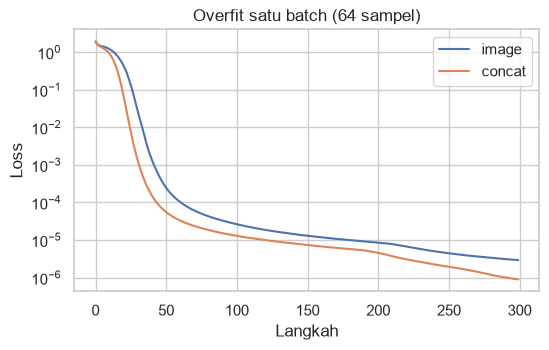

Hasil: lolos (loss < 0.05 dan akurasi >= 0.99).


In [15]:
def sanity_overfit(arch, n=64, steps=300, lr=1e-3):
    set_seed(SEED); model = build_model(arch, {**DEFAULT_CFG, "dropout": 0.0}).to(DEVICE); g = GD["train"]
    idx = torch.randperm(g["n"], generator=torch.Generator().manual_seed(SEED))[:n].to(DEVICE)
    img, sen, mask, y = g["img"][idx].float().div(255), g["sensor"][idx], g["mask"][idx], g["y"][idx]
    opt = torch.optim.Adam(model.parameters(), lr=lr); hist = []; model.train()
    for _ in range(steps):
        loss = F.cross_entropy(model(img, sen, mask), y); opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
    model.eval()
    with torch.no_grad():
        acc = (model(img, sen, mask).argmax(1) == y).float().mean().item()
    return hist, acc

sanity = {a: sanity_overfit(a) for a in ["image", "concat"]}
display(pd.DataFrame([{"Model": a, "Loss awal": h[0], "Loss akhir": h[-1], "Akurasi batch": acc} for a, (h, acc) in sanity.items()]).set_index("Model").round(4))
plt.figure(figsize=(6, 3.4))
for a, (h, _) in sanity.items(): plt.plot(h, label=a)
plt.yscale("log"); plt.xlabel("Langkah"); plt.ylabel("Loss"); plt.title("Overfit satu batch (64 sampel)"); plt.legend(); plt.show()
print("Hasil:", "lolos (loss < 0.05 dan akurasi >= 0.99)." if all(h[-1] < 0.05 and acc >= 0.99 for h, acc in sanity.values())
      else "belum lolos; periksa forward model, format label, dan preprocessing.")

,Selisih,Dipakai,Dasar
Teknik,,,
Label smoothing,0.0039,True,val Macro-F1
Per-line norm + aug,0.0029,False,F1 terbobot lini test
Modality dropout,-0.0112,False,rata-rata F1 lintas kondisi sensor


Selisih di bawah 0.003 dianggap noise dan tidak dipakai.
[final_s123] gated | 395K parameter
  ep  1 | loss 1.545 / 1.129 | macro-F1 0.174 / 0.399
  ep  2 | loss 0.892 / 0.764 | macro-F1 0.576 / 0.617
  ep  3 | loss 0.774 / 0.836 | macro-F1 0.643 / 0.598
  ep  4 | loss 0.709 / 0.779 | macro-F1 0.686 / 0.620
  ep  5 | loss 0.668 / 0.694 | macro-F1 0.714 / 0.692
  ep  6 | loss 0.635 / 0.666 | macro-F1 0.734 / 0.717
  ep  7 | loss 0.608 / 0.628 | macro-F1 0.748 / 0.740
  ep  8 | loss 0.579 / 0.628 | macro-F1 0.767 / 0.741
  ep  9 | loss 0.547 / 0.628 | macro-F1 0.785 / 0.751
  ep 10 | loss 0.518 / 0.571 | macro-F1 0.806 / 0.778
  ep 11 | loss 0.468 / 0.525 | macro-F1 0.838 / 0.814
  ep 12 | loss 0.426 / 0.494 | macro-F1 0.866 / 0.831
  ep 13 | loss 0.409 / 0.488 | macro-F1 0.873 / 0.833
  ep 14 | loss 0.404 / 0.487 | macro-F1 0.876 / 0.833
[final_s123] selesai 3294 detik | val Macro-F1 0.8333
[final_s2024] gated | 395K parameter
  ep  1 | loss 1.502 / 1.082 | macro-F1 0.206 / 0.440
  ep  

,Macro-F1,Accuracy,F1 lini A,F1 lini B,Best epoch
42,0.8385,0.8660,0.8744,0.7198,14.0000
123,0.8333,0.8643,0.8702,0.7064,13.0000
2024,0.8411,0.8688,0.8739,0.7302,14.0000
Rata-rata,0.8377,0.8664,0.8728,0.7188,13.6667
Std,0.0040,0.0023,0.0023,0.0119,0.5774


Macro-F1 validation: 0.8377 +/- 0.0040 (3 seed). Selisih antar model di bawah std ini bukan perbedaan nyata.


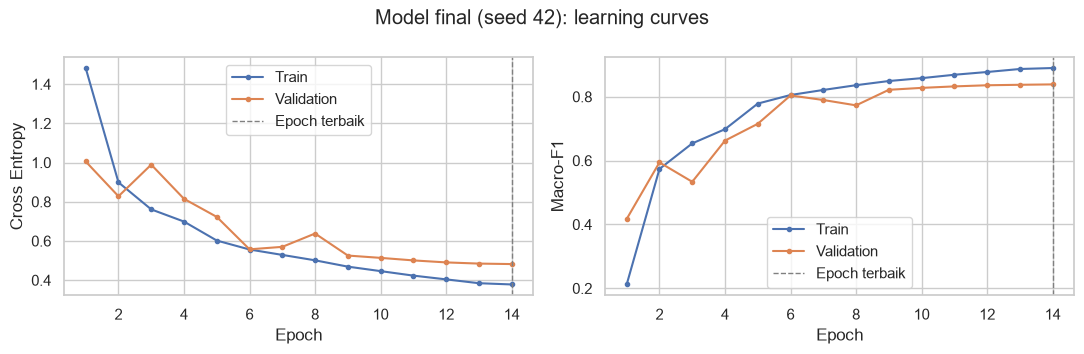

Epoch terbaik 14: train F1 0.890, val F1 0.839 (selisih +0.051) -> ada indikasi overfitting.


In [16]:
# Konfigurasi final: gabungkan teknik yang memberi perbaikan nyata (>= GAIN) di validation
GAIN = 0.003
v = lambda n, k="f1": RUNS[n]["val_metrics"][k]
use_ls = v(run_ls["name"]) - v(BEST_NAME) >= GAIN
use_dom = v(run_dom["name"], "f1_w") - v(BEST_NAME, "f1_w") >= GAIN
use_md = COND_AVG[run_md["name"]] - COND_AVG[BEST_NAME] >= GAIN
final_over = {"label_smoothing": 0.1 if use_ls else 0.0, "line_norm": bool(use_dom), "aug": bool(use_dom), "moddrop": bool(use_md)}
display(pd.DataFrame([
    {"Teknik": "Label smoothing", "Selisih": v(run_ls["name"]) - v(BEST_NAME), "Dipakai": use_ls, "Dasar": "val Macro-F1"},
    {"Teknik": "Per-line norm + aug", "Selisih": v(run_dom["name"], "f1_w") - v(BEST_NAME, "f1_w"), "Dipakai": use_dom, "Dasar": "F1 terbobot lini test"},
    {"Teknik": "Modality dropout", "Selisih": COND_AVG[run_md["name"]] - COND_AVG[BEST_NAME], "Dipakai": use_md, "Dasar": "rata-rata F1 lintas kondisi sensor"}]).set_index("Teknik").round(4))
print(f"Selisih di bawah {GAIN} dianggap noise dan tidak dipakai.")

SEEDS = [42, 123, 2024]; final_runs = {}
for s in SEEDS:
    expected = {**DEFAULT_CFG, **final_over, "arch": BEST_ARCH, "seed": s}
    same = next((r for r in RUNS.values() if r["cfg"] == expected), None)   # pakai ulang run yang konfigurasinya identik
    if same is not None:
        if same["ckpt"] != ARTIFACT_DIR / f"ckpt_final_s{s}.pt":
            shutil.copy(same["ckpt"], ARTIFACT_DIR / f"ckpt_final_s{s}.pt")
        final_runs[s] = RUNS[f"final_s{s}"] = same
    else:
        final_runs[s] = train_run(f"final_s{s}", BEST_ARCH, final_over, seed=s)

seed_df = pd.DataFrame([{"Seed": s, "Macro-F1": r["val_metrics"]["f1"], "Accuracy": r["val_metrics"]["acc"],
                         "F1 lini A": r["val_metrics"]["f1_A"], "F1 lini B": r["val_metrics"]["f1_B"], "Best epoch": r["best_epoch"]}
                        for s, r in final_runs.items()]).set_index("Seed")
display(pd.concat([seed_df, pd.DataFrame({"Rata-rata": seed_df.mean(), "Std": seed_df.std(ddof=1)}).T]).round(4))
SEED_MEAN, SEED_STD = seed_df["Macro-F1"].mean(), seed_df["Macro-F1"].std(ddof=1)
print(f"Macro-F1 validation: {SEED_MEAN:.4f} +/- {SEED_STD:.4f} (3 seed). Selisih antar model di bawah std ini bukan perbedaan nyata.")

fin = final_runs[SEED]; plot_history(fin, "Model final (seed 42): learning curves"); diagnose_fit(fin)

## 11. Evaluasi Model Final
Model final = rata-rata probabilitas tiga model seed (ensemble) jika Macro-F1 validation-nya tidak lebih rendah dari rata-rata model tunggal.

Macro-F1 validation: ensemble 3 seed 0.8481 | rata-rata model tunggal 0.8377 -> ensemble dipakai


,Accuracy,Precision,Recall,Macro-F1,F1 lini A,F1 lini B,F1 terbobot lini test
Model,,,,,,,
Model final,0.8752,0.8941,0.8115,0.8481,0.8826,0.7301,0.7962
Fusion + LS,0.8660,0.8749,0.8083,0.8385,0.8744,0.7198,0.7855
Gated fusion,0.8641,0.8737,0.8031,0.8346,0.8697,0.7118,0.7812
Concat fusion,0.8643,0.8679,0.8067,0.8343,0.8724,0.7052,0.7772
Fusion + per-line norm + aug,0.8561,0.8564,0.8077,0.8288,0.8580,0.7259,0.7842
Fusion + modality dropout,0.8397,0.8315,0.7586,0.7898,0.8278,0.6444,0.7296
Image-only,0.7302,0.6525,0.5664,0.5948,0.6464,0.3796,0.5092
Sensor-only,0.6621,0.4585,0.4604,0.4512,0.4567,0.4337,0.4433


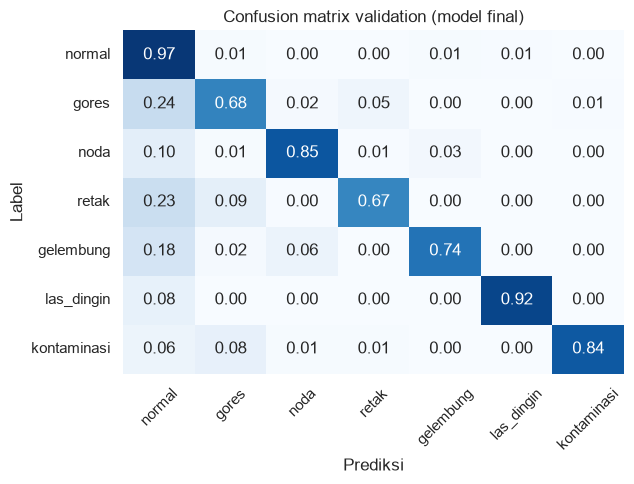

              precision    recall  f1-score   support

      normal      0.861     0.970     0.912      4778
       gores      0.814     0.683     0.743      1124
        noda      0.905     0.853     0.878       955
       retak      0.863     0.670     0.754       721
   gelembung      0.879     0.742     0.805       686
  las_dingin      0.967     0.919     0.943       865
 kontaminasi      0.971     0.843     0.902       471

    accuracy                          0.875      9600
   macro avg      0.894     0.812     0.848      9600
weighted avg      0.876     0.875     0.872      9600

F1 semua sensor hilang: model final 0.5480 | image-only 0.5943 -> BELUM memenuhi syarat (selisih maks 0.02)


In [17]:
def probs(model, g, cfg, **kw):
    return F.softmax(predict_logits(model, g, cfg, **kw), 1)

ens_val = torch.stack([probs(r["model"], GD["val"], r["cfg"]) for r in final_runs.values()]).mean(0)
ens_pred = ens_val.argmax(1).numpy(); ens_f1 = macro_f1(Y_VAL, ens_pred)
USE_ENSEMBLE = ens_f1 >= SEED_MEAN
print(f"Macro-F1 validation: ensemble 3 seed {ens_f1:.4f} | rata-rata model tunggal {SEED_MEAN:.4f} -> {'ensemble dipakai' if USE_ENSEMBLE else 'model seed 42 dipakai'}")
final_pred = ens_pred if USE_ENSEMBLE else final_runs[SEED]["val_logits"].argmax(1).numpy()

tab = metrics_table(NAMES_MAIN + [f"{BEST_ARCH}_ls", f"{BEST_ARCH}_dom", f"{BEST_ARCH}_md"],
                    {**LABELS, f"{BEST_ARCH}_ls": "Fusion + LS", f"{BEST_ARCH}_dom": "Fusion + per-line norm + aug", f"{BEST_ARCH}_md": "Fusion + modality dropout"})
mf = compute_metrics(Y_VAL, final_pred)
tab.loc["Model final"] = [mf["acc"], mf["prec"], mf["rec"], mf["f1"], macro_f1(Y_VAL[LINI_VAL == "A"], final_pred[LINI_VAL == "A"]),
                          macro_f1(Y_VAL[LINI_VAL == "B"], final_pred[LINI_VAL == "B"]), macro_f1(Y_VAL, final_pred, sample_weight=W_VAL)]
display(tab.round(4).sort_values("Macro-F1", ascending=False))

cm = confusion_matrix(Y_VAL, final_pred, labels=list(range(NUM_CLASSES)), normalize="true")
plt.figure(figsize=(6.5, 5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Prediksi"); plt.ylabel("Label"); plt.title("Confusion matrix validation (model final)"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print(classification_report(Y_VAL, final_pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES, digits=3, zero_division=0))

# Syarat sensor hilang: model final tidak boleh jauh di bawah image-only saat semua sensor hilang
fin_name = next(n for n, r in RUNS.items() if r is final_runs[SEED])
if fin_name not in COND_TABLE: cond_row(fin_name)
img_ref, fin_all = COND_TABLE["image_only"]["semua hilang"], COND_TABLE[fin_name]["semua hilang"]
print(f"F1 semua sensor hilang: model final {fin_all:.4f} | image-only {img_ref:.4f} -> {'memenuhi' if fin_all >= img_ref - 0.02 else 'BELUM memenuhi'} syarat (selisih maks 0.02)")

## 12. Prediksi Test dan Ekspor CSV
Checkpoint dimuat ulang dari disk agar yang dipakai benar-benar model yang tersimpan. Label test tidak dipakai.

In [18]:
def load_model(path):
    st = torch.load(path, map_location=DEVICE, weights_only=True); cfg = st["cfg"]
    m = build_model(cfg["arch"], cfg).to(DEVICE); m.load_state_dict(st["model"]); return m, cfg

use_seeds = SEEDS if USE_ENSEMBLE else [SEED]
loaded = [load_model(ARTIFACT_DIR / f"ckpt_final_s{s}.pt") for s in use_seeds]
chk = torch.stack([probs(m, GD["val"], c) for m, c in loaded]).mean(0).argmax(1).numpy()
print(f"Cek checkpoint: val Macro-F1 {macro_f1(Y_VAL, chk):.4f} (tercatat {macro_f1(Y_VAL, final_pred):.4f})")
assert abs(macro_f1(Y_VAL, chk) - macro_f1(Y_VAL, final_pred)) < 5e-3

GD["test"] = to_gpu(data["test"])
assert GD["test"]["n"] == len(test_meta) and (data["test"]["id_unit"] == test_meta["id_unit"].to_numpy()).all()
test_pred = torch.stack([probs(m, GD["test"], c) for m, c in loaded]).mean(0).argmax(1).numpy()

dist = pd.DataFrame({"Prediksi test (%)": pd.Series([ID2LABEL[i] for i in test_pred]).value_counts(normalize=True).reindex(CLASS_NAMES) * 100,
                     "Train (%)": train_meta["kelas"].value_counts(normalize=True).reindex(CLASS_NAMES) * 100}).round(2)
display(dist)
print("Sampel test tanpa sensor sama sekali (diprediksi dari gambar):", int((data["test"]["mask"].sum(1).numpy() == N_CHANNELS).sum()))

json.dump({"seeds": use_seeds, "ensemble": bool(USE_ENSEMBLE), "cfg": {k: v for k, v in final_runs[SEED]["cfg"].items() if k != "seed"},
           "val_macro_f1_ensemble": float(ens_f1), "val_macro_f1_seeds": {str(s): float(r["val_metrics"]["f1"]) for s, r in final_runs.items()},
           "seed_mean": float(SEED_MEAN), "seed_std": float(SEED_STD)}, open(ARTIFACT_DIR / "final_config.json", "w"), indent=2)

OUT_CSV = (Path("..") if Path.cwd().name == "kode" else Path(".")) / "prediksi_klasifikasi.csv"
pd.DataFrame({"id_unit": test_meta["id_unit"].to_numpy(), "kelas": [ID2LABEL[i] for i in test_pred]}).to_csv(OUT_CSV, index=False)
sub = pd.read_csv(OUT_CSV)
assert list(sub.columns) == ["id_unit", "kelas"] and len(sub) == len(test_meta) and sub["id_unit"].is_unique
assert sub.notna().all().all() and sub["kelas"].isin(CLASS_NAMES).all()
assert (sub["id_unit"].to_numpy() == test_meta["id_unit"].to_numpy()).all()
print(f"{OUT_CSV} valid: {len(sub):,} baris (harus 16.000), kolom {list(sub.columns)}")
display(sub.head(3))

try:
    from google.colab import files
    files.download(str(OUT_CSV))
except ImportError:
    print("Bukan di Colab. File tersimpan di:", OUT_CSV.resolve())

Cek checkpoint: val Macro-F1 0.8481 (tercatat 0.8481)


,Prediksi test (%),Train (%)
normal,60.12,49.77
gores,8.09,11.71
noda,8.31,9.94
retak,4.90,7.51
gelembung,6.06,7.15
las_dingin,8.32,9.01
kontaminasi,4.20,4.91


Sampel test tanpa sensor sama sekali (diprediksi dari gambar): 813
..\prediksi_klasifikasi.csv valid: 16,000 baris (harus 16.000), kolom ['id_unit', 'kelas']


,id_unit,kelas
0,U412019,gores
1,U929275,retak
2,U845264,normal


Bukan di Colab. File tersimpan di: D:\TELKOM\Semester 7\DL\UTS\prediksi_klasifikasi.csv


## 13. Ringkasan Hasil (untuk laporan)

In [19]:
f = lambda n: RUNS[n]["val_metrics"]["f1"]
print(f"Image-only            : {f('image_only'):.4f}")
print(f"Sensor-only           : {f('sensor_only'):.4f}")
print(f"Concat / Gated fusion : {f('concat_fusion'):.4f} / {f('gated_fusion'):.4f}")
print(f"Label smoothing       : {f(f'{BEST_ARCH}_ls') - f(BEST_NAME):+.4f} terhadap fusion baseline")
print(f"Domain shift          : selisih F1 lini A-B baseline {RUNS[BEST_NAME]['val_metrics']['f1_A'] - RUNS[BEST_NAME]['val_metrics']['f1_B']:.4f}"
      f" -> {RUNS[run_dom['name']]['val_metrics']['f1_A'] - RUNS[run_dom['name']]['val_metrics']['f1_B']:.4f} (per-line norm + aug)")
print(f"Sensor hilang         : rata-rata F1 lintas kondisi {COND_AVG[BEST_NAME]:.4f} -> {COND_AVG[run_md['name']]:.4f} (modality dropout)")
print(f"Model final           : {SEED_MEAN:.4f} +/- {SEED_STD:.4f} (3 seed), ensemble {ens_f1:.4f}")
print("Catatan: angka validation dipakai untuk memilih konfigurasi, jadi skor test bisa sedikit lebih rendah, terutama karena lini B (lebih sulit) mencakup 60% data test.")

Image-only            : 0.5948
Sensor-only           : 0.4512
Concat / Gated fusion : 0.8343 / 0.8346
Label smoothing       : +0.0039 terhadap fusion baseline
Domain shift          : selisih F1 lini A-B baseline 0.1579 -> 0.1321 (per-line norm + aug)
Sensor hilang         : rata-rata F1 lintas kondisi 0.7230 -> 0.7118 (modality dropout)
Model final           : 0.8377 +/- 0.0040 (3 seed), ensemble 0.8481
Catatan: angka validation dipakai untuk memilih konfigurasi, jadi skor test bisa sedikit lebih rendah, terutama karena lini B (lebih sulit) mencakup 60% data test.
